#Rating Prediction Using Random Forest

## 1. Data Loading and Inspection

In [2]:
#setup-library imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
#loading and inspecting dataset

df = pd.read_csv("../../data/features/07_rating_features.csv")

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print ("\nAll 34 column names:")
for column in df.columns:
    print(column)

print("\nDataset information:")
df.info()

print ("\nMissing values in each column:")
print(df.isnull().sum().to_string())

print("\nColumn data types:")
print(df.dtypes.to_string())

Dataset shape: (11508, 34)

First five rows:


,id,vote_average,vote_count,release_year,release_month,release_decade,log_budget,log_revenue,runtime,log_popularity,...,production_countries,spoken_languages,director,top_cast,keywords,title,original_title,overview,original_language,status
0,862,7.7,5415,1995.0,10.0,1990.0,17.216708,19.738573,81.0,3.133185,...,[United States of America],[English],John Lasseter,"[""Tom Hanks"", ""Tim Allen"", ""Don Rickles"", ""Jim...","[jealousy, toy, boy, friendship, friends, riva...",Toy Story,Toy Story,"Led by Woody, Andy's toys live happily in his ...",en,Released
1,8844,6.9,2413,1995.0,12.0,1990.0,17.989898,19.386893,104.0,2.891235,...,[United States of America],"[English, Français]",Joe Johnston,"[""Robin Williams"", ""Jonathan Hyde"", ""Kirsten D...","[board game, disappearance, based on children'...",Jumanji,Jumanji,When siblings Judy and Peter discover an encha...,en,Released
2,15602,6.5,92,1995.0,12.0,1990.0,0.000000,0.000000,101.0,2.542617,...,[United States of America],[English],Howard Deutch,"[""Walter Matthau"", ""Jack Lemmon"", ""Ann-Margret...","[fishing, best friend, duringcreditsstinger, o...",Grumpier Old Men,Grumpier Old Men,A family wedding reignites the ancient feud be...,en,Released
3,31357,6.1,34,1995.0,12.0,1990.0,16.588099,18.215526,127.0,1.580935,...,[United States of America],[English],Forest Whitaker,"[""Whitney Houston"", ""Angela Bassett"", ""Loretta...","[based on novel, interracial relationship, sin...",Waiting to Exhale,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",en,Released
4,11862,5.7,173,1995.0,2.0,1990.0,0.000000,18.153832,106.0,2.239381,...,[United States of America],[English],Charles Shyer,"[""Steve Martin"", ""Diane Keaton"", ""Martin Short...","[baby, midlife crisis, confidence, aging, daug...",Father of the Bride Part II,Father of the Bride Part II,Just when George Banks has recovered from his ...,en,Released



All 34 column names:
id
vote_average
vote_count
release_year
release_month
release_decade
log_budget
log_revenue
runtime
log_popularity
genre_count
has_collection
company_count
country_count
spoken_language_count
cast_size
crew_size
has_director
keyword_count
title_word_count
overview_word_count
title_differs_from_original
genres
production_companies
production_countries
spoken_languages
director
top_cast
keywords
title
original_title
overview
original_language
status

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 11508 entries, 0 to 11507
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           11508 non-null  int64  
 1   vote_average                 11508 non-null  float64
 2   vote_count                   11508 non-null  int64  
 3   release_year                 11506 non-null  float64
 4   release_month                11506 non-null  float64


## 2. Feature Selection

In [4]:
#Numerical and categorical features

feature_columns = [
    "release_year",
    "release_month",
    "release_decade",
    "log_budget",
    "runtime",
    "log_popularity",
    "genre_count",
    "has_collection",
    "company_count",
    "country_count",
    "spoken_language_count",
    "cast_size",
    "crew_size",
    "keyword_count",
    "title_word_count",
    "overview_word_count",
    "title_differs_from_original",
    "original_language"
]

#feature and target variable separation

X = df[feature_columns]
y = df["vote_average"]

#Result display
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

Feature shape: (11508, 18)
Target shape: (11508,)

Selected features:
['release_year', 'release_month', 'release_decade', 'log_budget', 'runtime', 'log_popularity', 'genre_count', 'has_collection', 'company_count', 'country_count', 'spoken_language_count', 'cast_size', 'crew_size', 'keyword_count', 'title_word_count', 'overview_word_count', 'title_differs_from_original', 'original_language']


## 3. Training, Validation, and Testing split

In [5]:
#dataset split into training and temporary sets

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

#temporary set split into validation and test sets

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

#Split sizes display

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Training set: (8055, 18)
Validation set: (1726, 18)
Test set: (1727, 18)


## 4. Preprocessing Data

In [6]:
#Numerical and categorical features identification

numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['release_year', 'release_month', 'release_decade', 'log_budget', 'runtime', 'log_popularity', 'genre_count', 'has_collection', 'company_count', 'country_count', 'spoken_language_count', 'cast_size', 'crew_size', 'keyword_count', 'title_word_count', 'overview_word_count', 'title_differs_from_original']

Categorical features: ['original_language']


In [7]:
#Numerical preprocessing pipeline

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

#Categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#Preprocessing pipeline

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 5. Random Forest Model Training

In [8]:
#Random forest model pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


## 6. Random Forest Hyperparameter Tuning

In [9]:
#Random Forest configurations

configurations = [
    {"n_estimators": 100, "max_depth": 10, "min_samples_split": 2},
    {"n_estimators": 100, "max_depth": 20, "min_samples_split": 2},
    {"n_estimators": 200, "max_depth": 10, "min_samples_split": 2},
    {"n_estimators": 200, "max_depth": 20, "min_samples_split": 5},
    {"n_estimators": 300, "max_depth": None, "min_samples_split": 2},
]

print("Number of configurations to test:", len(configurations))

Number of configurations to test: 5


In [11]:
#Train and evaluate each Random Forest configuration

results = []

for config in configurations:
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(**config, random_state=42))
    ])

    #Train model
    model_pipeline.fit(X_train, y_train)

    #Predict validation ratings
    y_val_pred = model_pipeline.predict(X_val)

    #Calculate ealuation metrics
    mae = mean_absolute_error(y_val, y_val_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
    r2 = r2_score(y_val, y_val_pred)

    results.append({
       "n_estimators": config["n_estimators"],
       "max_depth": config["max_depth"],
       "min_samples_split": config["min_samples_split"],
       "MAE": mae,
       "RMSE": rmse,
       "R2": r2
    })

#Validation results
results_df = pd.DataFrame(results)

print("Validation results:")
display(results_df.round(4))

Validation results:


,n_estimators,max_depth,min_samples_split,MAE,RMSE,R2
0,100,10.0,2,0.5726,0.7512,0.3581
1,100,20.0,2,0.5684,0.7465,0.3660
2,200,10.0,2,0.5724,0.7513,0.3579
3,200,20.0,5,0.5659,0.7442,0.3699
4,300,NaN,2,0.5664,0.7460,0.3668


## 7. Validation Performance Comparison

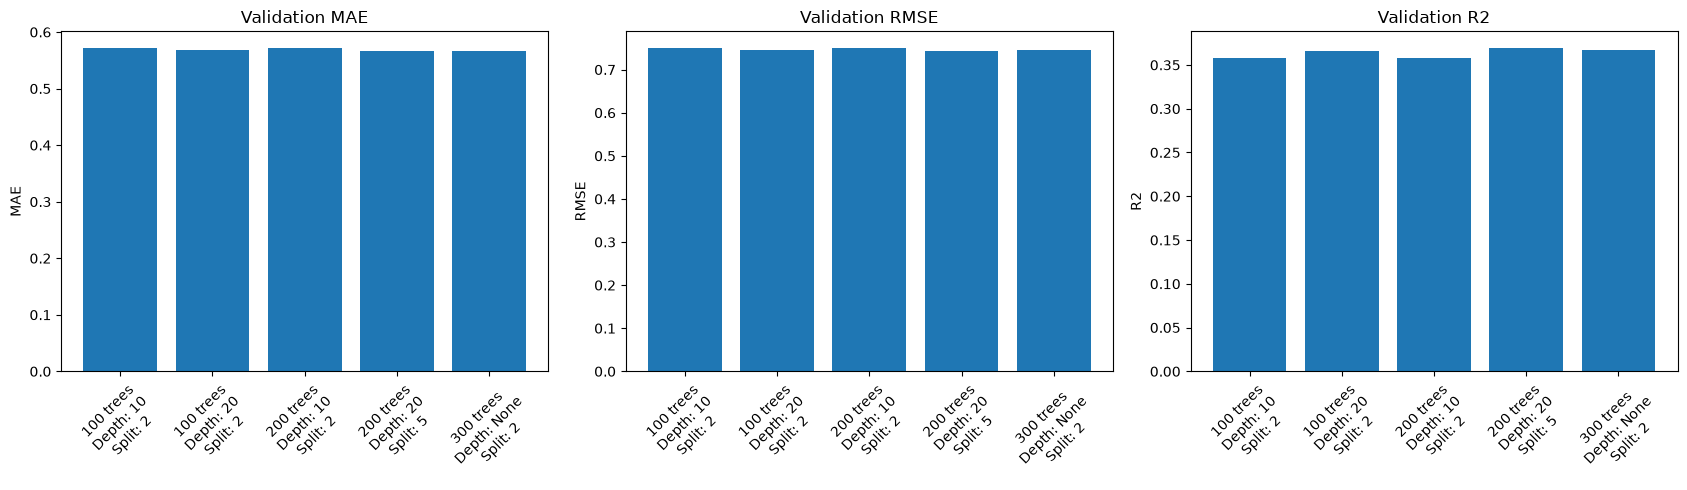

In [13]:
#validation performance across configurations

config_labels = [
    f"{config['n_estimators']} trees\nDepth: {config['max_depth']}\nSplit: {config['min_samples_split']}"
    for config in configurations
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

#MAE comparison
axes[0].bar(config_labels, results_df["MAE"])
axes[0].set_title("Validation MAE")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", labelrotation=45)

#RMSE comparison
axes[1].bar(config_labels, results_df["RMSE"])
axes[1].set_title("Validation RMSE")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", labelrotation=45)

#R2 comparison
axes[2].bar(config_labels, results_df["R2"])
axes[2].set_title("Validation R2")
axes[2].set_ylabel("R2")
axes[2].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

## 8. Final Model Evaluation

In [14]:
#Best Random Forest configuraion from validation results

best_index = results_df["MAE"].idxmin()
best_config = configurations[best_index]

print("Best configuration:", best_config)
      
#Train selected method using training set
best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(**best_config, random_state=42))
])

best_model.fit(X_train, y_train)

#Selected model evaluation once on the test set
y_test_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

#Final test results

print("\nFinal Test Results:")
print("MAE:", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R2:", round(test_r2, 4))


Best configuration: {'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 5}

Final Test Results:
MAE: 0.5648
RMSE: 0.7234
R2: 0.3897


## 9. Predicted vs. Actual Ratings

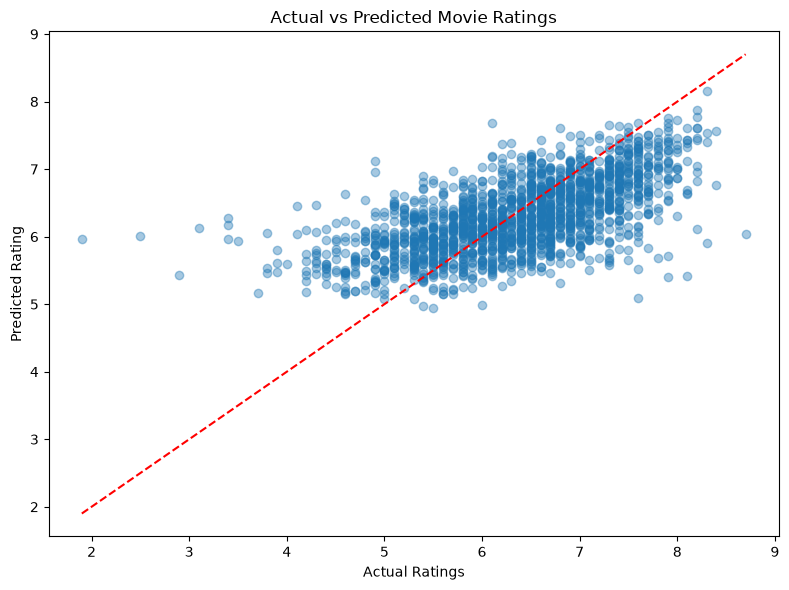

In [15]:
#Actual and predicted movie ratings comparison

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_test_pred, alpha=0.4)

#Reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted Movie Ratings")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Rating")
plt.tight_layout()
plt.show()

## 10. One-Movie Inference Example

In [16]:
#Movie sample selection from test set
sample_movie = X_test.iloc[[0]]

#Movie rating prediction
predicted_rating = best_model.predict(sample_movie)

#Movie input features and predicted rating
print("Movie input features:")
display(sample_movie)
print("Predicted movie rating:", round(predicted_rating[0], 2))

#actual rating comparison
actual_rating = y_test.iloc[0]
print("Actual movie rating:", actual_rating)

Movie input features:


,release_year,release_month,release_decade,log_budget,runtime,log_popularity,genre_count,has_collection,company_count,country_count,spoken_language_count,cast_size,crew_size,keyword_count,title_word_count,overview_word_count,title_differs_from_original,original_language
9485,2014.0,11.0,2010.0,0.0,94.0,1.795908,4,0,4,1,1,14.0,5.0,4,4,18,0,en


Predicted movie rating: 5.71
Actual movie rating: 5.5


## 11. Main Findings
The Random Forest model was trained using 18 numerical and categorical features to predict movie ratings ('vote_average').

5 hyperparameter configurations were tested and compared using validation MAE, RMSE, and R2. The best connfiguration used 200 trees, a maximum depth of 20, and a minimum samples split of 5.

The selected model achieved the following results on the test set:
-MAE: 0.5648
-RMSE: 0.7234
-R2: 0.3897

The Predicted vs. Actual visualization showed that the predictions were generally concentrated around the middle rating values. The model performed less accurately on some movies with unusually low or high ratings.

In the inference example, the model predicted a rating of 5.71 compared with the actual rating of 5.50 which was a difference of 0.21 points.

## 12. Residual Analysis (optional visualization)

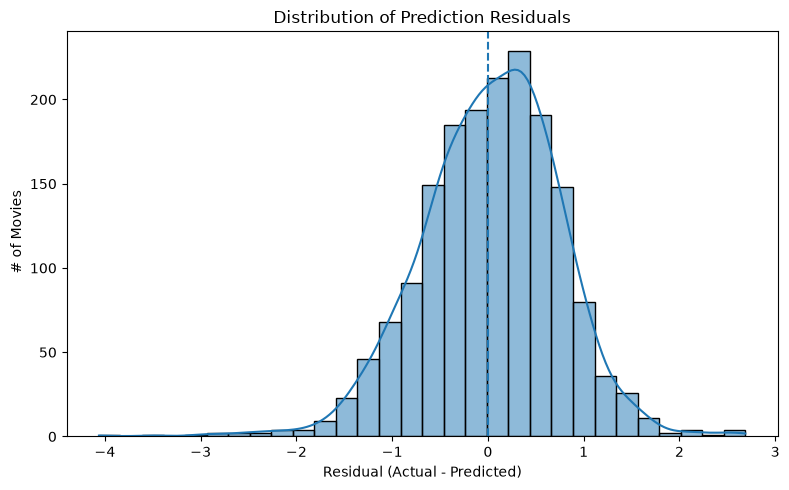

In [17]:
#Prediction residuals
residuals = y_test - y_test_pred

#plot residual distribution
plt.figure(figsize=(8,5))
sns.histplot(residuals, bins=30, kde=True)
plt.axvline(0, linestyle="--")
plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel(" # of Movies")
plt.tight_layout()
plt.show()